
# Project 3: Customer Churn / Sales Trend Analysis

## Project Overview

This project analyses an e-commerce sales dataset to identify monthly revenue trends, compare product categories, understand customer spending patterns, and develop actionable business recommendations.

**Tools:** Python, Pandas, NumPy, Matplotlib

**Dataset:** Synthetic e-commerce order data.


In [1]:

import pandas as pd
import numpy as np

# Reproducible random data
rng = np.random.default_rng(21)

# Number of orders
n_orders = 1500

# Generate the e-commerce dataset
orders = pd.DataFrame({
    "order_date": pd.Timestamp("2025-01-01") +
                  pd.to_timedelta(
                      rng.integers(0, 365, n_orders), unit="D"
                  ),

    "customer_id": rng.integers(1001, 1301, n_orders),

    "category": rng.choice(
        ["Electronics", "Fashion", "Home", "Books"],
        n_orders,
        p=[0.30, 0.35, 0.20, 0.15]
    ),

    "amount": rng.gamma(2.2, 550, n_orders).round(2)
})

orders.head()


,order_date,customer_id,category,amount
0,2025-04-21,1201,Electronics,1160.60
1,2025-10-13,1246,Electronics,863.04
2,2025-05-21,1060,Books,1506.42
3,2025-08-10,1247,Home,2035.15
4,2025-06-20,1292,Electronics,2374.34


In [2]:
# Check dataset dimensions
print("Dataset Shape:", orders.shape)

# Check column data types
print("\nDataset Information:")
orders.info()

# Check missing values
print("\nMissing Values:")
print(orders.isnull().sum())

# Check duplicate rows
print("\nDuplicate Rows:", orders.duplicated().sum())

Dataset Shape: (1500, 4)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 4 columns):
 #   Column       Non-Null Count  Dtype         
---  ------       --------------  -----         
 0   order_date   1500 non-null   datetime64[ns]
 1   customer_id  1500 non-null   int64         
 2   category     1500 non-null   object        
 3   amount       1500 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(1), object(1)
memory usage: 47.0+ KB

Missing Values:
order_date     0
customer_id    0
category       0
amount         0
dtype: int64

Duplicate Rows: 0


In [3]:
# Extract date features
orders["month"] = orders["order_date"].dt.month
orders["month_name"] = orders["order_date"].dt.month_name()
orders["weekday"] = orders["order_date"].dt.day_name()
orders["quarter"] = orders["order_date"].dt.quarter

orders.head()

,order_date,customer_id,category,amount,month,month_name,weekday,quarter
0,2025-04-21,1201,Electronics,1160.60,4,April,Monday,2
1,2025-10-13,1246,Electronics,863.04,10,October,Monday,4
2,2025-05-21,1060,Books,1506.42,5,May,Wednesday,2
3,2025-08-10,1247,Home,2035.15,8,August,Sunday,3
4,2025-06-20,1292,Electronics,2374.34,6,June,Friday,2


In [4]:
monthly_sales = orders.groupby("month_name")["amount"].sum()

monthly_sales

,amount
month_name,
April,164116.94
August,147442.89
December,150906.96
February,138004.23
January,146360.91
July,155424.12
June,122242.94
March,136309.44
May,150107.36


In [5]:
monthly_sales = orders.groupby("month")["amount"].sum().sort_index()

monthly_sales

,amount
month,
1,146360.91
2,138004.23
3,136309.44
4,164116.94
5,150107.36
6,122242.94
7,155424.12
8,147442.89
9,140102.61


In [6]:
monthly_growth = monthly_sales.pct_change() * 100

monthly_analysis = pd.DataFrame({
    "Revenue": monthly_sales,
    "Growth (%)": monthly_growth
})

monthly_analysis.round(2)

,Revenue,Growth (%)
month,,
1,146360.91,NaN
2,138004.23,-5.71
3,136309.44,-1.23
4,164116.94,20.40
5,150107.36,-8.54
6,122242.94,-18.56
7,155424.12,27.14
8,147442.89,-5.14
9,140102.61,-4.98


In [7]:
best_month = monthly_sales.idxmax()
worst_month = monthly_sales.idxmin()

print("Best Revenue Month:", best_month)
print("Highest Revenue:", round(monthly_sales.max(), 2))

print("\nLowest Revenue Month:", worst_month)
print("Lowest Revenue:", round(monthly_sales.min(), 2))

Best Revenue Month: 4
Highest Revenue: 164116.94

Lowest Revenue Month: 6
Lowest Revenue: 122242.94


In [8]:
import matplotlib.pyplot as plt


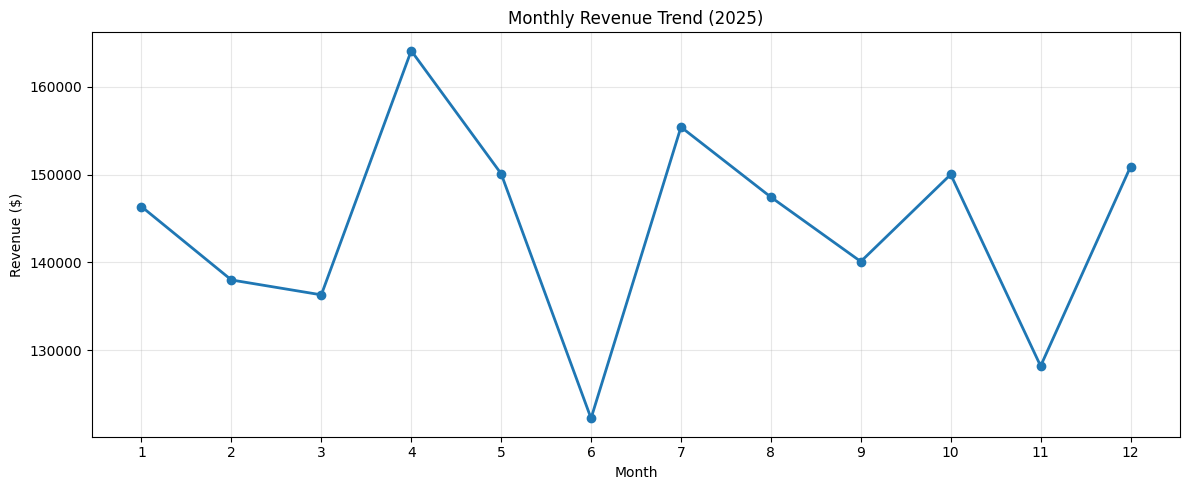

In [9]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

plt.title("Monthly Revenue Trend (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [10]:
category_analysis = orders.groupby("category")["amount"].agg(
    Total_Revenue="sum",
    Average_Order_Value="mean",
    Number_of_Orders="count"
)

category_analysis = category_analysis.round(2)

category_analysis

,Total_Revenue,Average_Order_Value,Number_of_Orders
category,,,
Books,283943.20,1158.95,245
Electronics,524413.21,1155.10,454
Fashion,565121.54,1119.05,505
Home,355759.51,1201.89,296


In [11]:
monthly_category = orders.pivot_table(
    index="month_name",
    columns="category",
    values="amount",
    aggfunc="sum"
)

monthly_category.round(2)

category,Books,Electronics,Fashion,Home
month_name,,,,
April,26819.94,57860.14,56784.21,22652.65
August,33480.98,46462.36,32567.93,34931.62
December,15827.74,45579.08,46204.99,43295.15
February,42175.96,37784.78,33242.21,24801.28
January,25785.59,42949.14,55337.69,22288.49
July,18749.57,51337.48,47246.70,38090.37
June,18168.08,36193.80,43210.57,24670.49
March,15139.40,40437.83,56738.47,23993.74
May,29474.71,49411.96,45444.60,25776.09


In [12]:
customer_spending = orders.groupby("customer_id")["amount"].sum()

customer_spending = customer_spending.sort_values(ascending=False)

top_10_count = int(len(customer_spending) * 0.10)

top_10_revenue = customer_spending.head(top_10_count).sum()

total_revenue = customer_spending.sum()

top_10_share = (top_10_revenue / total_revenue) * 100

print("Total Customers:", len(customer_spending))
print("Top 10% Customers:", top_10_count)
print("Revenue Share of Top 10%:", round(top_10_share, 2), "%")

Total Customers: 295
Top 10% Customers: 29
Revenue Share of Top 10%: 19.59 %


In [13]:
print("Highest Revenue Category:")
print(category_analysis["Total_Revenue"].idxmax())

print("\nLowest Revenue Category:")
print(category_analysis["Total_Revenue"].idxmin())

print("\nBest Revenue Month:")
print(monthly_sales.idxmax())

print("\nLowest Revenue Month:")
print(monthly_sales.idxmin())

Highest Revenue Category:
Fashion

Lowest Revenue Category:
Books

Best Revenue Month:
4

Lowest Revenue Month:
6


In [14]:
print("April Revenue:", round(monthly_sales.loc[4], 2))
print("June Revenue:", round(monthly_sales.loc[6], 2))

April Revenue: 164116.94
June Revenue: 122242.94


# Customer Churn / Sales Trend Analysis
## Business Brief

### 1. Business Objective
Analyse the generated e-commerce sales dataset to identify monthly revenue trends, category performance and high-value customers.

### 2. Key Findings

- **Total customers:** 295
- **Highest revenue category:** Fashion — ₹565,121.54
- **Lowest revenue category:** Books — ₹283,843.20
- **Highest revenue month:** April — ₹164,116.94
- **Lowest revenue month:** June — ₹122,242.94
- **Top 10% of customers:** 29 customers contributed 19.59% of total revenue.

### 3. Business Recommendations

1. **Strengthen Fashion sales:** Maintain availability of popular Fashion products and test targeted promotions, as Fashion generated the highest category revenue.
2. **Investigate June's revenue decline:** Compare demand, pricing and product availability during June before planning seasonal campaigns.
3. **Improve customer retention:** Test a loyalty programme for high-value customers and monitor repeat purchases and revenue.

### 4. Conclusion
The analysis indicates that Fashion is the strongest revenue-generating category, while June recorded the lowest monthly revenue. The highest-spending 10% of customers contributed 19.59% of revenue. These findings can guide further investigation and targeted business decisions.

### 5. Dataset Disclosure
The analysis uses a generated/simulated e-commerce dataset, not real customer transaction records.

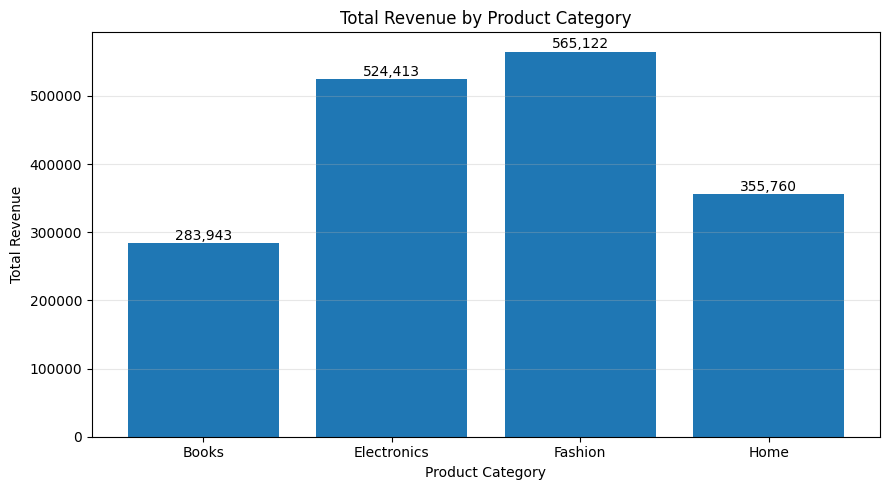

In [15]:
plt.figure(figsize=(9, 5))

plt.bar(
    category_analysis.index,
    category_analysis["Total_Revenue"]
)
for i, value in enumerate(category_analysis["Total_Revenue"]):
    plt.text(i, value + 5000, f"{value:,.0f}", ha="center")

plt.title("Total Revenue by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

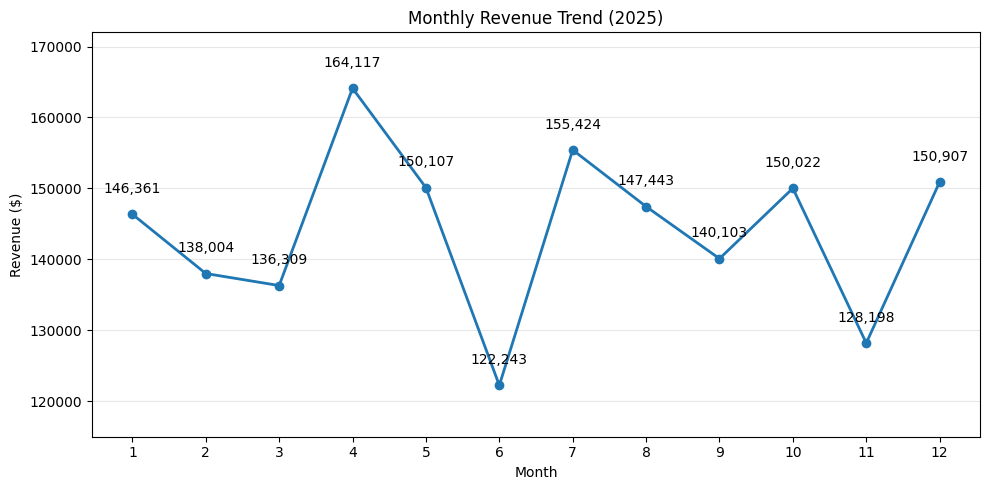

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker="o",
    linewidth=2
)

for i, value in enumerate(monthly_sales.values):
    plt.text(i + 1, value + 3000, f"{value:,.0f}", ha="center")

plt.title("Monthly Revenue Trend (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue ($)")
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)

plt.ylim(115000, 172000)
plt.tight_layout()
plt.show()

In [17]:
monthly_analysis = monthly_sales.to_frame(name="Revenue")

monthly_analysis["Growth (%)"] = (
    monthly_analysis["Revenue"].pct_change() * 100
)

monthly_analysis = monthly_analysis.round(2)

monthly_analysis

,Revenue,Growth (%)
month,,
1,146360.91,NaN
2,138004.23,-5.71
3,136309.44,-1.23
4,164116.94,20.40
5,150107.36,-8.54
6,122242.94,-18.56
7,155424.12,27.14
8,147442.89,-5.14
9,140102.61,-4.98


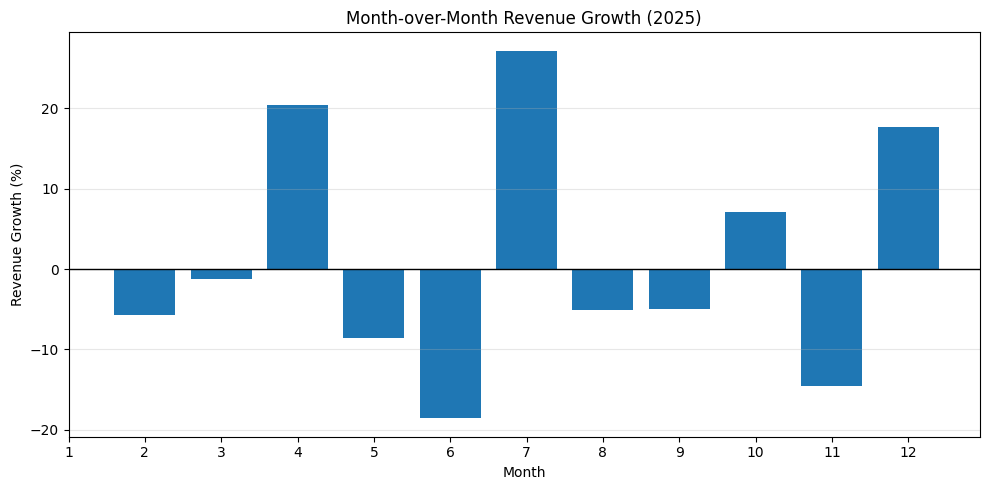

In [18]:
plt.figure(figsize=(10, 5))

plt.bar(
    monthly_analysis.index,
    monthly_analysis["Growth (%)"]
)

plt.title("Month-over-Month Revenue Growth (2025)")
plt.xlabel("Month")
plt.ylabel("Revenue Growth (%)")
plt.axhline(y=0, color="black", linewidth=1)
plt.xticks(range(1, 13))
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [19]:
category_analysis

,Total_Revenue,Average_Order_Value,Number_of_Orders
category,,,
Books,283943.20,1158.95,245
Electronics,524413.21,1155.10,454
Fashion,565121.54,1119.05,505
Home,355759.51,1201.89,296


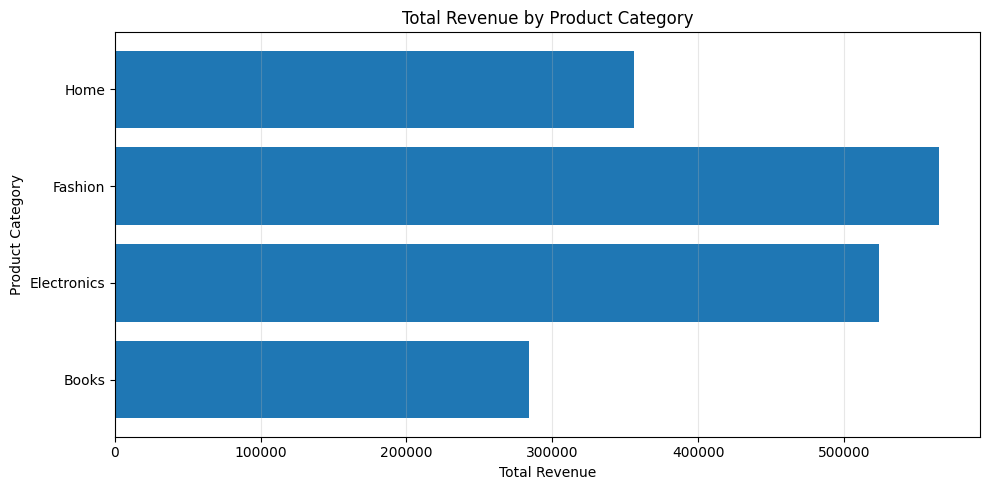

In [20]:
plt.figure(figsize=(10, 5))

plt.barh(
    category_analysis.index,
    category_analysis["Total_Revenue"]
)

plt.title("Total Revenue by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

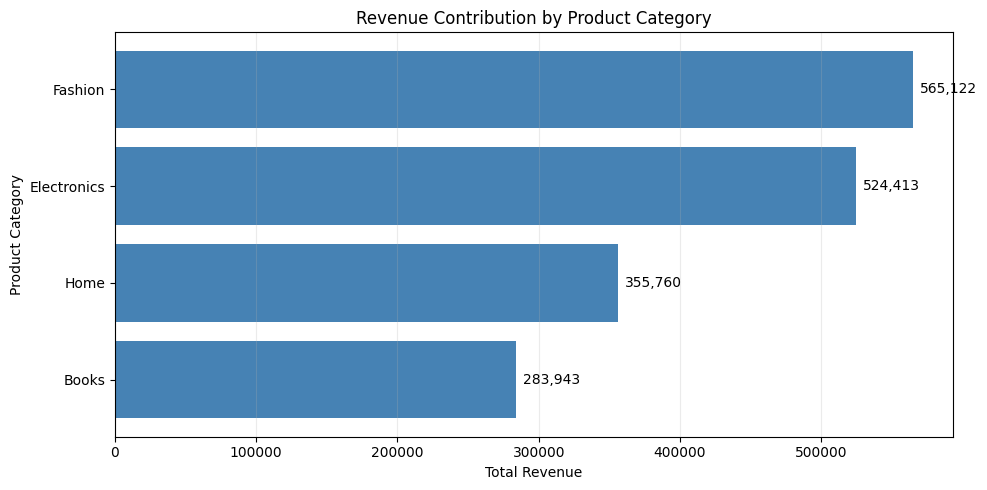

In [21]:
category_sorted = category_analysis.sort_values(
    "Total_Revenue",
    ascending=True
)

plt.figure(figsize=(10, 5))

bars = plt.barh(
    category_sorted.index,
    category_sorted["Total_Revenue"],
    color="steelblue"
)

for bar in bars:
    value = bar.get_width()
    plt.text(
        value + 5000,
        bar.get_y() + bar.get_height() / 2,
        f"{value:,.0f}",
        va="center"
    )

plt.title("Revenue Contribution by Product Category")
plt.xlabel("Total Revenue")
plt.ylabel("Product Category")
plt.grid(axis="x", alpha=0.25)

plt.tight_layout()
plt.show()

In [22]:
customer_spending.head(10)

,amount
customer_id,
1188,15370.72
1266,14920.75
1247,13900.24
1095,13657.90
1264,13055.22
1045,12899.45
1175,12820.23
1178,12814.80
1296,12132.51


In [23]:
top_10_count = int(len(customer_spending) * 0.10)

print("Total Customers:", len(customer_spending))
print("Top 10% Customer Count:", top_10_count)

Total Customers: 295
Top 10% Customer Count: 29


In [24]:
top_10_revenue = customer_spending.head(top_10_count).sum()

print("Top 10% Customer Revenue:", round(top_10_revenue, 2))

Top 10% Customer Revenue: 338687.31


In [25]:
total_revenue = customer_spending.sum()

top_10_share = (top_10_revenue / total_revenue) * 100

print("Total Revenue:", round(total_revenue, 2))
print("Revenue Share of Top 10%:", round(top_10_share, 2), "%")

Total Revenue: 1729237.46
Revenue Share of Top 10%: 19.59 %


## 7. Business Recommendations

Based on the sales trends, product category performance, and customer spending analysis, the following recommendations can help improve business performance.

### 1. Strengthen the Fashion Category
Fashion generated the highest revenue (565,121.54), making it the strongest-performing category. The business should maintain product availability and test targeted promotions to build on its performance.

### 2. Improve Sales During Low-Revenue Months
June recorded the lowest monthly revenue (122,242.94), while April recorded the highest (164,116.94). The business should investigate possible reasons for the June decline and test targeted campaigns during weaker months.

### 3. Develop Customer Retention Strategies
The top 10% of customers (29 out of 295) contributed 19.50% of total revenue. The business could pilot a loyalty programme for these customers and measure whether it improves repeat purchases and revenue.

# Project 3: Customer Churn / Sales Trend Analysis

## Business Brief

### 1. Context
This project analyses an e-commerce sales dataset to identify monthly revenue trends, product category performance, and valuable customer segments.

### 2. Key Findings
- Fashion generated the highest category revenue: 565,121.54.
- Books generated the lowest category revenue: 283,943.20.
- April recorded the highest monthly revenue: 164,116.94.
- June recorded the lowest monthly revenue: 122,242.94.
- The top 10% of customers (29 out of 295) contributed 19.50% of total revenue.

### 3. Recommendations
- Maintain Fashion product availability and test targeted promotions.
- Investigate the June revenue decline and test campaigns during weaker months.
- Pilot a loyalty programme for high-value customers and measure its impact.

### 4. Next Steps
- Monitor monthly revenue and category performance.
- Track customer repeat purchases.
- Evaluate the results of promotional and loyalty campaigns.

## Data Source and Disclaimer

This project uses a synthetically generated e-commerce sales dataset created with Python and NumPy for educational and analytical purposes. It does not contain real customer or transaction records.